In [1]:
using CSVFiles

In [3]:
using LinearAlgebra
using DataFrames
using DataFrames
using Measurements
import Measurements: value, uncertainty

[ Info: Precompiling StructUtilsTablesExt [06a1ca1f-7bc7-53d2-8cfe-f45bf2a4bdd3](cache misses: wrong dep version loaded (1))
[ Info: Precompiling StructUtilsTablesExt [06a1ca1f-7bc7-53d2-8cfe-f45bf2a4bdd3] (cache misses: wrong dep version loaded (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


In [4]:
##alles was hier kommt sind nur rundungsfunktionen und eine voreinstellung für die Achsenbeschriftung


using CSV
using CSVFiles
using CairoMakie

using DataFrames
using Measurements
import Measurements: value, uncertainty
using Statistics



using Random, Statistics

function first_significant_digit(x::Real)
    x == 0 && return 0  # Sonderfall: Wenn x genau 0 ist, gibt es keine signifikante Stelle, also gib 0 zurück.

    absx = abs(x)  # Der Betrag der Zahl wird genommen, damit negative Vorzeichen ignoriert werden.

    # Berechne die Zehnerpotenz, in der sich die erste signifikante Stelle befindet.
    # log10(absx) gibt den dekadischen Logarithmus. floor(Int, ...) rundet nach unten auf ganze Zahl.
    exponent = floor(Int, log10(absx))

    # Teile absx durch 10^exponent, um die Zahl in den Bereich [1,10) zu bringen
    # Beispiel: aus 456 → 4.56, aus 0.00456 → 4.56
    significand = absx / 10.0^exponent

    # Jetzt holen wir die ganzzahlige Ziffer vor dem Komma, das ist die erste signifikante Ziffer
    return floor(Int, significand)
end


"""
    round_measurement(m::Measurement; sigdigits_error::Int=1)

Rundet erst die Unsicherheit von `m` auf `sigdigits_error` signifikante Stellen
und rundet dann den Messwert auf dieselbe Genauigkeit (Dezimalstellen),
liefert einen neuen `Measurement`. Sigdigits_error wird automatisch auf den richtigen wert gesetzt durch if bedingung 
wenn first sig digit =1 oder 2, wird eine weitere stelle hinzugenommen.

input: ein measurement, output: ein measurement. Kann punktweise angewendet werden
"""
function round_measurement(m::Measurement)
    # 1) Unsicherheit extrahieren und auf sigdigits_error sig. Stellen runden
    u = uncertainty(m)
    if first_significant_digit(u)<3
        sigdigits_error=2
    else
        sigdigits_error=1
    end
    #println(sigdigits_error)

    u_r = round(u; sigdigits=sigdigits_error)

    
    if u_r==0 #wenn gauß versagt, normalverteilung und stw
        

    # Ziehe N Stichproben aus einer Normalverteilung und berechne KINETISCHE ENERGIE!!!
    p_samples = randn(100_000) .* 0.05  # p ~ N(0, σp=0.05) kein plan warum, aber die 0.05 sind auf jkeden fall der fehler vorher

    # Berechne kinetische Energie für jede Probe
    E_samples = p_samples.^2 ./ (2)

    # Mittelwert und Standardabweichung der Energie
    E_mean = mean(E_samples)
    E_std = std(E_samples)
    
    u_r = round(E_std; sigdigits=sigdigits_error)
        #println(u_r)
    end
    
    
    
    
    
    # 2) Anzahl Dezimalstellen bestimmen:
    #    Wenn u_r = x * 10^e  (mit 1 ≤ x < 10), dann ist e = floor(log10(u_r))
    #    und wir benötigen -e  Dezimalstellen (für e ≤ 0)
    e = floor(Int, log10(u_r))
       # println(e)
    if first_significant_digit(u)<3
        dec = max(0, -e) +1
    else
        dec = max(0, -e)
    end
    #dec = max(0, -e)
    #println(dec, log(12,u_r))

    # 3) Wert runden und neuen Measurement erstellen
    v_r = round(value(m); digits=dec)
    return measurement(v_r, u_r)
end

# Beispiel
m = measurement(0.023456, 0.0120236789)
println("Original: ", value(m))                  # 1.23456 ± 0.06789
m2 = round_measurement(m)
println("Gerundet: ", value(m2))  # z.B. 1.23(7) → ±0.07, Wert 1.23




[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0](cache misses: wrong dep version loaded (1))
[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0] (cache misses: wrong dep version loaded (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling MeasurementsMakieExt [255515a4-532d-589b-944b-ec83cf1d0fb0](cache misses: wrong dep version loaded (1))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling MeasurementsMakieExt [255515a4-532d-589b-944b-ec83cf1d0fb0] (cache misses: wrong dep version loaded (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


Original: 0.023456
Gerundet: 0.023


In [5]:

function generate_reflections(hmax,nth)
    sc  = Dict{Int, Vector{Tuple{Int,Int,Int}}}()
    bcc = Dict{Int, Vector{Tuple{Int,Int,Int}}}()
    fcc = Dict{Int, Vector{Tuple{Int,Int,Int}}}()

    for h in 0:hmax, k in 0:hmax, l in 0:hmax
        if h == 0 && k == 0 && l == 0
            continue
        else
        N = h^2 + k^2 + l^2
        hkl = (h,k,l)

        # --- SC: alle erlaubten Reflexe ---
        if length(sc) == nth
            if N < maximum(keys(sc))
                delete!(sc, maximum(keys(sc)))
            end
        end 

        if length(fcc) == nth
            if N < maximum(keys(fcc))
                delete!(fcc, maximum(keys(fcc)))
            end
        end 

        if length(bcc) == nth
            if N < maximum(keys(bcc))
                delete!(bcc, maximum(keys(bcc)))
            end
        end 


        if length(sc) < nth
            push!(get!(sc, N, Vector{Tuple{Int,Int,Int}}()), hkl)
        end

        # --- BCC: h+k+l gerade ---
        if length(bcc) < nth
            if (h + k + l) % 2 == 0
                push!(get!(bcc, N, Vector{Tuple{Int,Int,Int}}()), hkl) 
            end
        end

        # --- FCC: alle h,k,l entweder alle gerade oder alle ungerade ---
        if length(fcc) < nth
            if (h % 2 == k % 2 == l % 2)
                push!(get!(fcc, N, Vector{Tuple{Int,Int,Int}}()), hkl)
            end
        end
    end
    end
    sc_sorted = [(N, sc[N]) for N in sort(collect(keys(sc)))]
    bcc_sorted = [(N, bcc[N]) for N in sort(collect(keys(bcc)))]
    fcc_sorted = [(N, fcc[N]) for N in sort(collect(keys(fcc)))]
    return sc_sorted, bcc_sorted, fcc_sorted
end


generate_reflections (generic function with 1 method)

In [6]:
sc,bcc,fcc = generate_reflections(5,3)


([(1, [(0, 0, 1), (0, 1, 0), (1, 0, 0)]), (2, [(0, 1, 1), (1, 0, 1), (1, 1, 0)]), (3, [(1, 1, 1)])], [(2, [(0, 1, 1), (1, 0, 1), (1, 1, 0)]), (4, [(0, 0, 2), (0, 2, 0), (2, 0, 0)]), (6, [(2, 1, 1)])], [(3, [(1, 1, 1)]), (4, [(0, 0, 2), (0, 2, 0), (2, 0, 0)]), (8, [(2, 2, 0)])])

In [7]:
sc_sorted = [(N, sc[N]) for N in sort(collect(keys(sc)))]
bcc_sorted = [(N, bcc[N]) for N in sort(collect(keys(bcc)))]
fcc_sorted = [(N, fcc[N]) for N in sort(collect(keys(fcc)))]

3-element Vector{Tuple{Int64, Tuple{Int64, Vector{Tuple{Int64, Int64, Int64}}}}}:
 (1, (3, [(1, 1, 1)]))
 (2, (4, [(0, 0, 2), (0, 2, 0), (2, 0, 0)]))
 (3, (8, [(2, 2, 0)]))

In [8]:
function table(th)
    row1 = round_measurement.(th ./2)
    row2 = round_measurement.(sin.((th ./2).*pi ./180))
    sc, bcc, fcc = generate_reflections(length(th)*2, length(th))
    row3 = []
    row4 = []
    row5 = []
    row6 = []
    row7 = []
    row8 = []
    for i in 1:min(length(sc), length(bcc), length(fcc))
        push!(row3, sc[i][2][1])
        push!(row4, round(sqrt(sc[i][1]), sigdigits=3))

        push!(row5, bcc[i][2][1])
        push!(row6, round(sqrt(bcc[i][1]), sigdigits=3))
        
        push!(row7, fcc[i][2][1])
        push!(row8, round(sqrt(fcc[i][1]), sigdigits=3))
    end
    DataFrame(θ=row1, sinθ=row2, sc=row3, sqrtsc=row4, bcc=row5, sqrtbcc=row6, fcc=row7, sqrtfcc=row8)
end


table (generic function with 1 method)

In [9]:
t=table(measurement.([0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360],0.1))
(th = t[:,2])
(root = t[:,8])
delth = 0


0

In [10]:
using CSV


In [2]:
function nice_ticks_and_labels(x; n_ticks= 3, n_labels=1, sigdigit=5)
    ordermax = Float64(floor(Int, log10(abs(maximum(x)))))
    ordermin = Float64(floor(Int, log10(abs(minimum(x)))))
    order = max(ordermax, ordermin)
    println("order = $order, ordermin = $ordermin, ordermax = $ordermax")
    if maximum(x)>0
     nmax = Float64(floor(Int, (abs(maximum(x)) / 10^order))+1)# erste Ziffer
    else
     nmax = Float64(floor(Int, (abs(maximum(x)) / 10^order))) # erste Ziffer   
    end
    if minimum(x) <0 
        nmin = Float64(floor(Int, (abs(minimum(x)) / 10^order))+1)  # erste Ziffer
    else
        nmin = Float64(floor(Int, (abs(minimum(x)) / 10^order)))  # erste Ziffer
    end
    
    println("nmin=", nmin ,"nmax=" , nmax)
    sign_nmax=1
    sign_nmin=1
    if minimum(x) < 0
        sign_nmin=sign_nmin*-1
    end
    if maximum(x) < 0 
        sign_nmax= sign_nmax*-1
    end
    ntotal=nmax*sign_nmax - nmin*sign_nmin
    if ntotal >= 10
        if mod(ntotal,2)==0
            ntotal=ntotal/2
            if mod(nmax,2)!=0
                nmax=nmax+1
                nmin=nmin+1
                ntotal=ntotal+1
            end
        else 
            if mod(nmax,2)==0
            nmin=nmin+1
            else 
            nmax=nmax+1
            end
            ntotal=(ntotal+1)/2
        end
    end
    
    tick_max = nmax * 10^order *sign_nmax
    tick_min = nmin * 10^order *sign_nmin
    #=if minimum(x) < 0          #mit signnmin,max gelöst
        tick_min= -tick_min   
    end
    if maximum(x) < 0 
        tick_max= -tick_max
end =#
    println("ntotal= $ntotal " )
    orderntotal = Float64(floor(Int, log10(ntotal)))
    println("nticks ", n_ticks * ntotal +1)
    println("tick_min = $tick_min", "tick_max = $tick_max")
            
    #ticks = round.(collect((-tick_min:0.5 *10^(orderntotal)/n_ticks:tick_max)) ; digits =sigdigit)  # feinere Tick-Striche
       ticks= round.(collect(range(tick_min, tick_max, length= n_ticks * Int(ntotal) +1 )) ;digits = sigdigit)
    
    # Beschriftete Zahlen: 10 gleichmäßig
    labels = round.(collect(range(tick_min, tick_max, n_labels * Int(ntotal) +1)) ;digits = sigdigit)
        println("labels = $labels ", "ticks=$ticks")

    return ticks, labels
end

function alignedlabels(ticks, labels; atol=0.0001)
    aligned = String[]
    for x in ticks
        match = findfirst(lbl -> isapprox(x, lbl; atol=atol, rtol=0), labels)
        if match == nothing
            push!(aligned, "")
        else
            push!(aligned, string(labels[match]))
        end
    end
    return aligned
end



alignedlabels (generic function with 1 method)

order = 1.0, ordermin = 0.0, ordermax = 1.0
nmin=0.0nmax=2.0
ntotal= 2.0 
nticks 9.0
tick_min = 0.0tick_max = 20.0
labels = [0.0, 5.0, 10.0, 15.0, 20.0] ticks=[0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0]
order = 1.0, ordermin = 0.0, ordermax = 1.0
nmin=0.0nmax=2.0
ntotal= 2.0 
nticks 9.0
tick_min = 0.0tick_max = 20.0
labels = [0.0, 5.0, 10.0, 15.0, 20.0] ticks=[0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0]
order = 1.0, ordermin = 0.0, ordermax = 1.0
nmin=0.0nmax=2.0
ntotal= 2.0 
nticks 9.0
tick_min = 0.0tick_max = 20.0
labels = [0.0, 5.0, 10.0, 15.0, 20.0] ticks=[0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0]
order = 1.0, ordermin = 0.0, ordermax = 1.0
nmin=0.0nmax=2.0
ntotal= 2.0 
nticks 9.0
tick_min = 0.0tick_max = 20.0
labels = [0.0, 5.0, 10.0, 15.0, 20.0] ticks=[0.0, 2.5, 5.0, 7.5, 10.0, 12.5, 15.0, 17.5, 20.0]


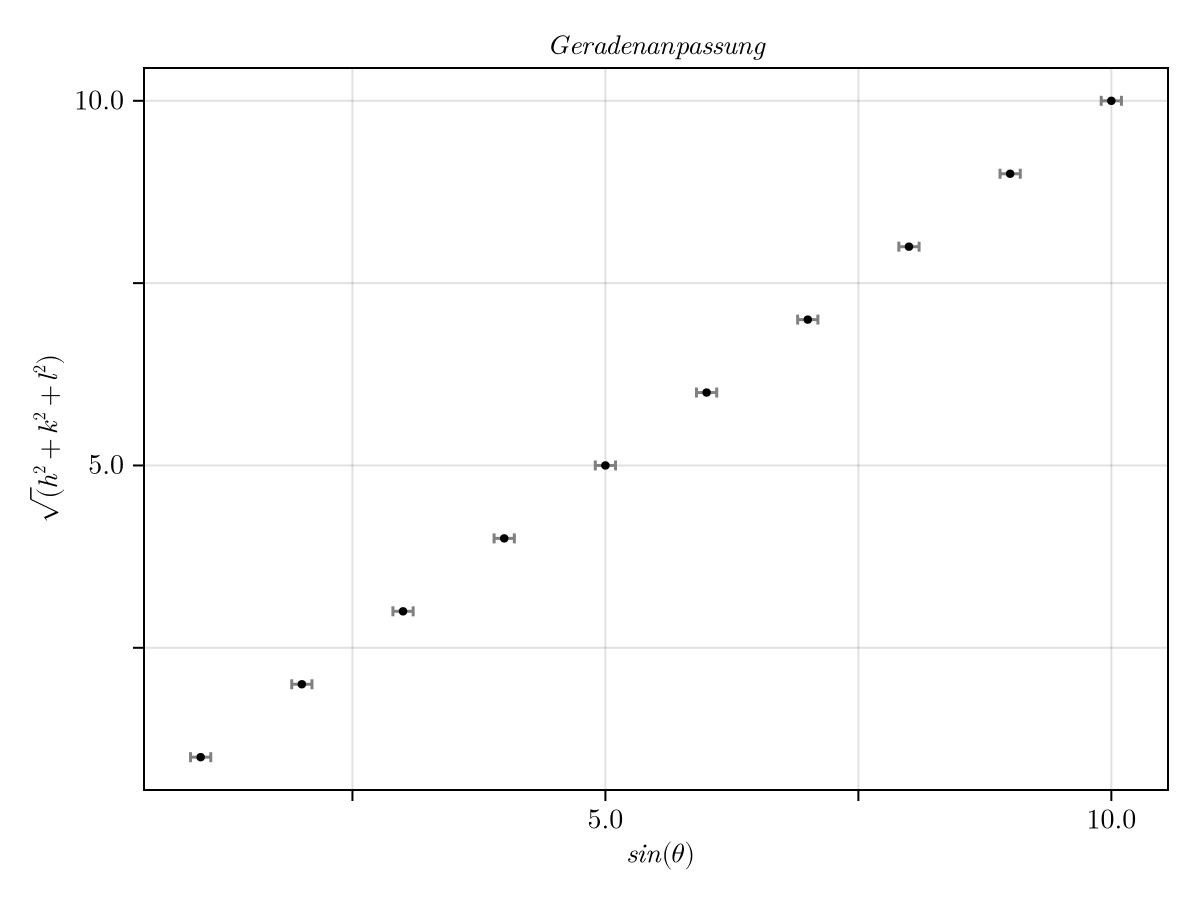

In [11]:
th=measurement.([1,2,3,4,5,6,7,8,9,10],0.1)
root=[1,2,3,4,5,6,7,8,9,10]
    

x = value.(th)##ANPASSEN##
y = root ##ANPASSEN##
#Fehler-Array mit gleichem Fehler
Δx= uncertainty.(th)
Δy= 0   
#=for i in 1:length(x)
    push!(Δx,ΔV) ###ANPASSEN##
    push!(Δy,ΔT) ##ANPASSEN##
end=#
#=for i in 1:length(x)
    push!(Δx,ΔV) ###ANPASSEN##
    push!(Δy,ΔT) ##ANPASSEN##
end=#

with_theme(theme_latexfonts()) do
    fig = Figure()
    ax = Axis(fig[1,1])
    #Fehlerbalken
    #errorbars!(ax, x, y, Δy, color=:grey, whiskerwidth = 5)
    errorbars!(ax, x, y, Δx, color=:grey, whiskerwidth = 5, direction = :x)
    #Messwerte
    scatter!(ax,x, y, markersize = 6, color=:black)
    
    ax.title = L"$Geradenanpassung$" ##ANPASSEN##


    #Skalierung der x-Achse ##ANPASSEN##
xticks = nice_ticks_and_labels(x,  n_labels=2, n_ticks=4)[1]
xticklabels = nice_ticks_and_labels(x,  n_labels=2, n_ticks=4)[2]
aligned_xlabels = alignedlabels(xticks, xticklabels)
#Skalierung der y-Achse ##ANPASSEN##
yticks = nice_ticks_and_labels(y,  n_labels=2, n_ticks=4)[1]
yticklabels = nice_ticks_and_labels(y,  n_labels=2, n_ticks=4)[2]   
aligned_ylabels = alignedlabels(yticks, yticklabels)
ax.xlabel = L" $sin(\theta)$" ##ANPASSEN##
ax.ylabel = L"$\sqrt(h^2 +k^2 +l^2)$  " ##ANPASSEN##

ax.xticks = (xticks, aligned_xlabels)
ax.yticks = (yticks, aligned_ylabels) 

#axislegend(ax; position=(:left, :top))
    #plot speichern
    #save("Messung_E_A.png", fig, px_per_unit = 2) ##ANPASSEN##

    fig
end


In [41]:
messung = (DataFrame(load(raw"C:\Users\va\Uni\Praktikum\Praktikum_B\Festkoerperphysik\Roentgennografische_Methoden\Gespeicherte_Fits\Probe_1_Gewichteter_Mittelwert.csv")))

Row,Peak_Label,Weighted_Mean_Theta,Error_Weighted_Mean_Theta
,Float64,Float64,Float64
1,27.86,13.9478,0.00267699
2,32.2,16.0989,0.00177885
3,45.94,22.9601,0.000431764
4,54.31,27.1589,0.0184154
5,56.91,28.4623,0.00107912
6,66.6,33.3286,0.00483305
7,73.4,36.7266,0.0194789
8,75.66,37.8573,0.00366704
9,84.33,42.1894,0.00302309


In [42]:

Probe_1 = measurement.(messung[:,1], messung[:,3])


14-element Vector{Measurement{Float64}}:
  27.86 ± 0.0027
   32.2 ± 0.0018
  45.94 ± 0.00043
  54.31 ± 0.018
  56.91 ± 0.0011
   66.6 ± 0.0048
   73.4 ± 0.019
  75.66 ± 0.0037
  84.33 ± 0.003
  90.69 ± 0.012
 101.42 ± 0.0052
  108.0 ± 0.013
  110.3 ± 0.0023
 119.66 ± 0.0031

In [43]:
werte= table(Probe_1)
th1 = werte[:,2]
sc  = werte[:,4]
bcc = werte[:,6]
fcc = werte[:,8]
save("Wertetabelle.csv", werte)
werte
#print(value.(th1))
#th1 = [0.24116, 0.277734, 0.389847, 0.45609, 0.476852, 0.54931, sin(36.5/180*pi), 0.61353, 0.67127,sin(45/180*pi), 0.77395, sin(53/180*pi)]

Row,θ,sinθ,sc,sqrtsc,bcc,sqrtbcc,fcc,sqrtfcc
,Measurem…,Measurem…,Any,Any,Any,Any,Any,Any
1,13.93±0.0013,0.240736±2.3e-5,"(0, 0, 1)",1.0,"(0, 1, 1)",1.41,"(1, 1, 1)",1.73
2,16.1±0.0009,0.277315±1.5e-5,"(0, 1, 1)",1.41,"(0, 0, 2)",2.0,"(0, 0, 2)",2.0
3,22.97±0.00022,0.390249±3.0e-6,"(1, 1, 1)",1.73,"(1, 1, 2)",2.45,"(0, 2, 2)",2.83
4,27.155±0.009,0.4564±0.00014,"(0, 0, 2)",2.0,"(0, 2, 2)",2.83,"(1, 1, 3)",3.32
5,28.455±0.0005,0.476468±8.0e-6,"(0, 1, 2)",2.24,"(0, 1, 3)",3.16,"(2, 2, 2)",3.46
6,33.3±0.0024,0.54902±4.0e-5,"(1, 1, 2)",2.45,"(2, 2, 2)",3.46,"(0, 0, 4)",4.0
7,36.7±0.01,0.59763±0.00014,"(0, 2, 2)",2.83,"(1, 2, 3)",3.74,"(1, 3, 3)",4.36
8,37.83±0.0018,0.613321±2.5e-5,"(0, 0, 3)",3.0,"(0, 0, 4)",4.0,"(0, 2, 4)",4.47
9,42.165±0.0015,0.671268±2.0e-5,"(0, 1, 3)",3.16,"(0, 3, 3)",4.24,"(2, 2, 4)",4.9


In [44]:
using LsqFit



In [45]:
model(x, p) = p[1].*x .+ p[2]

p0 = [1.0,0.0]


2-element Vector{Float64}:
 1.0
 0.0

Die Steigung mit fehler von Probe 3 ist 6.044577349802264 0.004442901431937154
Die Steigung mit fehler von Probe 2 ist 4.5833821447867535 0.1628069547477739
Die Steigung mit fehler von Probe 1 ist 7.366856329878522 0.13912315668949737
order = -1.0, ordermin = -1.0, ordermax = -1.0
nmin=2.0nmax=9.0
ntotal= 7.0 
nticks 29.0
tick_min = 0.2tick_max = 0.9
labels = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9] ticks=[0.2, 0.225, 0.25, 0.275, 0.3, 0.325, 0.35, 0.375, 0.4, 0.425, 0.45, 0.475, 0.5, 0.525, 0.55, 0.575, 0.6, 0.625, 0.65, 0.675, 0.7, 0.725, 0.75, 0.775, 0.8, 0.825, 0.85, 0.875, 0.9]
order = -1.0, ordermin = -1.0, ordermax = -1.0
nmin=2.0nmax=9.0
ntotal= 7.0 
nticks 281.0
tick_min = 0.2tick_max = 0.9
labels = [0.2, 0.20909, 0.21818, 0.22727, 0.23636, 0.24545, 0.25455, 0.26364, 0.27273, 0.28182, 0.29091, 0.3, 0.30909, 0.31818, 0.32727, 0.33636, 0.34545, 0.35455, 0.36364, 0.37273, 0.38182, 0.39091, 0.4, 0.40909, 0.41818, 0.42727, 0.43636, 0.44545,

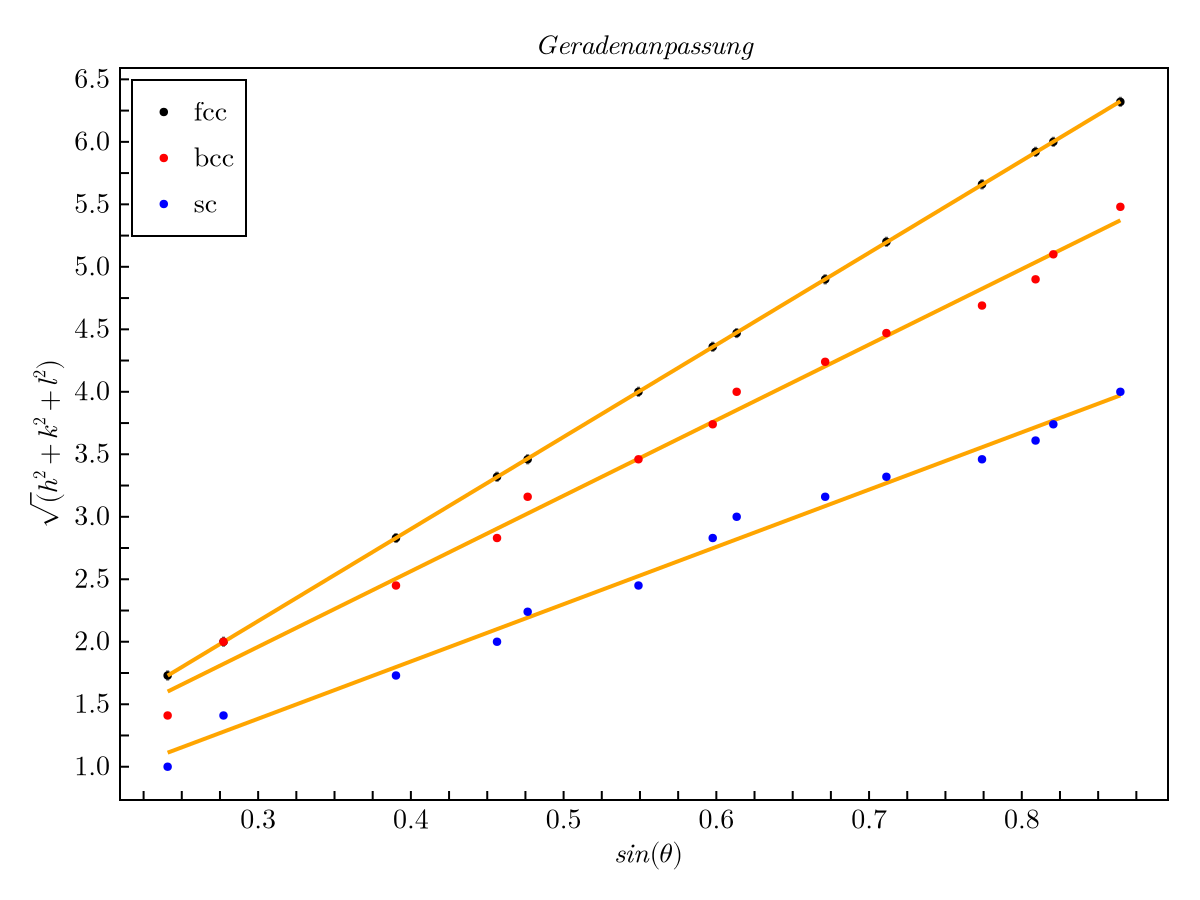

In [ ]:
#x = th1
x = value.(th1)##ANPASSEN##
y1 = fcc ##ANPASSEN##
y2 = bcc ##ANPASSEN##
y3 = sc  ##ANPASSEN##
#Fehler-Array mit gleichem Fehler
yfit(x,m,b)=m*x+b
Δx= delth
Δy= 0   
fit1 = curve_fit(model, x, y1, p0)
fit2 = curve_fit(model, x, y2, p0)
fit3 = curve_fit(model, x, y3, p0)
p1=fit1.param
dp1 = stderror(fit1)
p2=fit2.param
dp2 = stderror(fit2)
p3=fit3.param
dp3 = stderror(fit3)
println("Die Steigung mit fehler von Probe 3 ist ", p2[1] ," ", dp1[1]);
println("Die Steigung mit fehler von Probe 2 ist ", p3[1] , " ",dp2[1]);
println("Die Steigung mit fehler von Probe 1 ist ", p1[1] ," " ,dp3[1]);
#=for i in 1:length(x)
    push!(Δx,ΔV) ###ANPASSEN##
    push!(Δy,ΔT) ##ANPASSEN##
end=#
#=for i in 1:length(x)
    push!(Δx,ΔV) ###ANPASSEN##
    push!(Δy,ΔT) ##ANPASSEN##
end=#

with_theme(theme_latexfonts()) do
    fig = Figure()
    ax = Axis(fig[1,1], xgridvisible = false,
    ygridvisible = false,
    xtickalign = 1,
    ytickalign = 1,)
    #Fehlerbalken
    #errorbars!(ax, x, y, Δy, color=:grey, whiskerwidth = 5)
    errorbars!(ax, x, y1, Δx, color=:grey, whiskerwidth = 5, direction = :x)
    #Messwerte
    scatter!(ax,x, y1, markersize = 6, color=:black, label= "fcc")
    lines!(ax, [x[1], x[end]],  [yfit(x[1], p1[1], p1[2]), yfit(x[length(x)], p1[1], p1[2])], linewidth = 2, color = :orange)
    lines!(ax, [x[1], x[end]], [ yfit(x[1], p2[1], p2[2]), yfit(x[length(x)], p2[1], p2[2])], linewidth = 2, color = :orange)
    lines!(ax, [x[1], x[end]], [yfit(x[1], p3[1], p3[2]), yfit(x[length(x)], p3[1], p3[2])], linewidth = 2, color = :orange)
    scatter!(ax,x, y2, markersize = 6, color=:red, label = "bcc")
    scatter!(ax,x, y3, markersize = 6, color=:blue, label= "sc")
    
    ax.title = L"$Geradenanpassung$" ##ANPASSEN##


    #Skalierung der x-Achse ##ANPASSEN##
xticks = nice_ticks_and_labels(x, n_labels=2, n_ticks=4)[1]
xticklabels = nice_ticks_and_labels(x, n_labels=11, n_ticks=40)[2]
aligned_xlabels = alignedlabels(xticks, xticklabels)
#Skalierung der y-Achse ##ANPASSEN##
yticks = nice_ticks_and_labels(y1, n_labels=2, n_ticks = 4)[1]
yticklabels = nice_ticks_and_labels(y1, n_labels=2, n_ticks=4)[2]   
aligned_ylabels = alignedlabels(yticks, yticklabels)
ax.xlabel = L" $sin(\theta)$" ##ANPASSEN##
ax.ylabel = L"$\sqrt(h^2 +k^2 +l^2)$  " ##ANPASSEN##

ax.xticks = (xticks, aligned_xlabels)
ax.yticks = (yticks, aligned_ylabels) 

axislegend(ax; position=(:left, :top))
    #plot speichern
    #save("Messung_gerade_Probe1.png", fig, px_per_unit = 2) ##ANPASSEN##

    fig
end
